In [5]:
import pandas as pd

master = pd.read_csv("master_table.csv")
folds = pd.read_csv("folds.csv")
sar = pd.read_csv("sar_features.csv")
optical = pd.read_csv("s2_features.csv")

print("Master:", master.shape)
print("Folds:", folds.shape)
print("SAR:", sar.shape)
print("Optical:", optical.shape)

print("Unique master fields:", master.field_id.nunique())
print("Unique SAR fields:", sar.field_id.nunique())
print("Unique optical fields:", optical.field_id.nunique())

print("Fold distribution:")
print(folds["fold"].value_counts().sort_index())

print("SAR missing values:", sar.isna().sum().sum())
print("Optical missing values:", optical.isna().sum().sum())
print(folds.groupby("block")["fold"].nunique().value_counts())

Master: (1206, 9)
Folds: (1206, 3)
SAR: (1206, 44)
Optical: (1206, 38)
Unique master fields: 1206
Unique SAR fields: 1206
Unique optical fields: 1206
Fold distribution:
fold
0    322
1    260
2    261
3    190
4    173
Name: count, dtype: int64
SAR missing values: 0
Optical missing values: 10
fold
1    76
Name: count, dtype: int64


In [6]:
verification = pd.DataFrame({
    "Dataset": ["Master", "SAR", "Optical"],
    "Total_Fields": [
        len(master), len(sar), len(optical)
    ],
    "Unique_Fields": [
        master.field_id.nunique(),
        sar.field_id.nunique(),
        optical.field_id.nunique()
    ],
    "Missing_Values": [
        master.isna().sum().sum(),
        sar.isna().sum().sum(),
        optical.isna().sum().sum()
    ]
})

verification.to_csv("dataset_verification.csv", index=False)

folds["fold"].value_counts().sort_index().rename_axis(
    "fold"
).reset_index(name="field_count").to_csv(
    "fold_distribution.csv", index=False
)

print("CSV files saved successfully!")

CSV files saved successfully!


In [10]:
print("Master vs SAR:",
      set(master.field_id) == set(sar.field_id))

print("Master vs Optical:",
      set(master.field_id) == set(optical.field_id))

print("SAR vs Optical:",
      set(sar.field_id) == set(optical.field_id))

# Checking if all 3 datasets use the same fold assignments
check = folds.groupby("field_id")["fold"].nunique()

print("Fields with multiple fold assignments:", (check > 1).sum())
print("Fields with missing fold assignments:", master.field_id.nunique() - len(check))
print("Total unique spatial blocks:", folds["block"].nunique())

Master vs SAR: True
Master vs Optical: True
SAR vs Optical: True
Fields with multiple fold assignments: 0
Fields with missing fold assignments: 0
Total unique spatial blocks: 76


In [9]:
missing = optical.isna().sum()

print(missing[missing > 0])
print("\nTotal missing values:", optical.isna().sum().sum())

s2_ndre_mean    2
s2_ndre_std     2
s2_ndre_max     2
s2_ndre_min     2
s2_ndre_amp     2
dtype: int64

Total missing values: 10


In [12]:
ndre_cols = [
    "s2_ndre_mean",
    "s2_ndre_std",
    "s2_ndre_max",
    "s2_ndre_min",
    "s2_ndre_amp"
]

print(optical.loc[
    optical[ndre_cols].isna().any(axis=1),
    ["field_id"] + ndre_cols
])

print("Missing values per affected field:")

affected = optical.loc[
    optical[ndre_cols].isna().any(axis=1)
]

print(affected.isna().sum(axis=1))

                                        field_id  s2_ndre_mean  s2_ndre_std  \
182  Argentina_DUP1_farm28_field315_soybean_2021           NaN          NaN   
663    Argentina_DUP1_farm9_field98_soybean_2024           NaN          NaN   

     s2_ndre_max  s2_ndre_min  s2_ndre_amp  
182          NaN          NaN          NaN  
663          NaN          NaN          NaN  
Missing values per affected field:
182    5
663    5
dtype: int64


In [13]:
print("SAR columns:")
print(sar.columns.tolist())

print("\nOptical columns:")
print(optical.columns.tolist())

print("\nMaster columns:")
print(master.columns.tolist())

SAR columns:
['field_id', 'sar_n_dates', 'sar_vv_mean', 'sar_vv_std', 'sar_vv_max', 'sar_vv_min', 'sar_vv_amp', 'sar_vv_peak_frac', 'sar_vh_mean', 'sar_vh_std', 'sar_vh_max', 'sar_vh_min', 'sar_vh_amp', 'sar_vh_peak_frac', 'sar_vh_minus_vv_mean', 'sar_vh_minus_vv_std', 'sar_vh_minus_vv_max', 'sar_vh_minus_vv_min', 'sar_vh_minus_vv_amp', 'sar_vh_minus_vv_peak_frac', 'sar_vh_div_vv_mean', 'sar_vh_div_vv_std', 'sar_vh_div_vv_max', 'sar_vh_div_vv_min', 'sar_vh_div_vv_amp', 'sar_vh_div_vv_peak_frac', 'sar_rvi_mean', 'sar_rvi_std', 'sar_rvi_max', 'sar_rvi_min', 'sar_rvi_amp', 'sar_rvi_peak_frac', 'sar_vv_bin1', 'sar_vh_bin1', 'sar_vv_bin2', 'sar_vh_bin2', 'sar_vv_bin3', 'sar_vh_bin3', 'sar_vv_bin4', 'sar_vh_bin4', 'sar_vv_bin5', 'sar_vh_bin5', 'sar_vv_bin6', 'sar_vh_bin6']

Optical columns:
['field_id', 's2_n_images', 's2_ndvi_bin1', 's2_ndvi_bin2', 's2_ndvi_bin3', 's2_ndvi_bin4', 's2_ndvi_bin5', 's2_ndvi_bin6', 's2_ndvi_mean', 's2_ndvi_std', 's2_ndvi_max', 's2_ndvi_min', 's2_ndvi_amp', 's2_

In [14]:
labels = master[["field_id", "label"]]
fold_info = folds[["field_id", "fold"]]

# Preparing SAR-only
sar_data = labels.merge(sar.drop(columns=["sar_n_dates"]), on="field_id")
sar_data = sar_data.merge(fold_info, on="field_id")

# Preparing Optical-only
optical_data = labels.merge(optical.drop(columns=["s2_n_images"]), on="field_id")
optical_data = optical_data.merge(fold_info, on="field_id")

# Preparing Fusion
fused_features = sar.drop(columns=["sar_n_dates"]).merge(
    optical.drop(columns=["s2_n_images"]),
    on="field_id"
)

fused_data = labels.merge(fused_features, on="field_id")
fused_data = fused_data.merge(fold_info, on="field_id")

print("SAR:", sar_data.shape)
print("Optical:", optical_data.shape)
print("Fusion:", fused_data.shape)

SAR: (1206, 45)
Optical: (1206, 39)
Fusion: (1206, 81)


In [15]:
for name, df in [
    ("SAR", sar_data),
    ("Optical", optical_data),
    ("Fusion", fused_data)
]:
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Duplicate IDs:", df.field_id.duplicated().sum())
    print("Missing labels:", df.label.isna().sum())
    print("Missing folds:", df.fold.isna().sum())
    print("Missing feature values:",
          df.drop(columns=["field_id", "label", "fold"]).isna().sum().sum())


SAR
Rows: 1206
Duplicate IDs: 0
Missing labels: 0
Missing folds: 0
Missing feature values: 0

Optical
Rows: 1206
Duplicate IDs: 0
Missing labels: 0
Missing folds: 0
Missing feature values: 10

Fusion
Rows: 1206
Duplicate IDs: 0
Missing labels: 0
Missing folds: 0
Missing feature values: 10


In [16]:
sar_data.to_csv("sar_model_data.csv", index=False)
optical_data.to_csv("optical_model_data.csv", index=False)
fused_data.to_csv("fusion_model_data.csv", index=False)

print("All three datasets saved successfully!")

All three datasets saved successfully!


In [18]:
import task2_3_sar
models = task2_3_sar.models()
print("Available models:", list(models.keys()))

print("SAR:", sar_data["fold"].value_counts().sort_index().to_dict())
print("Optical:", optical_data["fold"].value_counts().sort_index().to_dict())
print("Fusion:", fused_data["fold"].value_counts().sort_index().to_dict())

Available models: ['LogReg', 'RandomForest', 'SVM_RBF', 'XGBoost']
SAR: {0: 322, 1: 260, 2: 261, 3: 190, 4: 173}
Optical: {0: 322, 1: 260, 2: 261, 3: 190, 4: 173}
Fusion: {0: 322, 1: 260, 2: 261, 3: 190, 4: 173}


In [20]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import pandas as pd
import numpy as np
import os

os.makedirs("results", exist_ok=True)

def evaluate_models(data, feature_cols, models, tag):

    results = []
    labels = sorted(data["label"].unique())

    for name, model_factory in models.items():

        predictions = np.empty(len(data), dtype=object)

        for fold in sorted(data["fold"].unique()):

            train = data["fold"] != fold
            test = data["fold"] == fold

            model = model_factory()

            model.fit(
                data.loc[train, feature_cols],
                data.loc[train, "label"]
            )

            predictions[test.to_numpy()] = model.predict(
                data.loc[test, feature_cols]
            )

        y_true = data["label"].to_numpy()

        results.append({
            "Approach": tag,
            "Model": name,
            "Fields": len(data),
            "Accuracy": accuracy_score(y_true, predictions),
            "Precision": precision_score(
                y_true, predictions, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions, average="macro", zero_division=0
            ),
            "Macro_F1": f1_score(
                y_true, predictions, average="macro"
            ),
            "Weighted_F1": f1_score(
                y_true, predictions, average="weighted"
            )
        })

        pd.DataFrame({
            "field_id": data["field_id"],
            "label": y_true,
            "pred": predictions,
            "fold": data["fold"]
        }).to_csv(f"results/pred_{tag}_{name}.csv", index=False)

        cm = confusion_matrix(y_true, predictions, labels=labels)

        pd.DataFrame(
            cm, index=labels, columns=labels
        ).to_csv(f"results/confusion_{tag}_{name}.csv")

        report = classification_report(
            y_true, predictions, labels=labels,
            zero_division=0, output_dict=True
        )

        pd.DataFrame(report).transpose().to_csv(
            f"results/classification_{tag}_{name}.csv"
        )

        print(f"{tag} | {name} | Accuracy: {accuracy_score(y_true, predictions):.4f} | Macro-F1: {f1_score(y_true, predictions, average='macro'):.4f}")

    result_df = pd.DataFrame(results)
    result_df.to_csv(f"results/results_{tag}.csv", index=False)

    return result_df

In [21]:
sar_features = [
    c for c in sar_data.columns
    if c.startswith("sar_")
]

print("Total SAR features:", len(sar_features))
print(sar_features)

Total SAR features: 42
['sar_vv_mean', 'sar_vv_std', 'sar_vv_max', 'sar_vv_min', 'sar_vv_amp', 'sar_vv_peak_frac', 'sar_vh_mean', 'sar_vh_std', 'sar_vh_max', 'sar_vh_min', 'sar_vh_amp', 'sar_vh_peak_frac', 'sar_vh_minus_vv_mean', 'sar_vh_minus_vv_std', 'sar_vh_minus_vv_max', 'sar_vh_minus_vv_min', 'sar_vh_minus_vv_amp', 'sar_vh_minus_vv_peak_frac', 'sar_vh_div_vv_mean', 'sar_vh_div_vv_std', 'sar_vh_div_vv_max', 'sar_vh_div_vv_min', 'sar_vh_div_vv_amp', 'sar_vh_div_vv_peak_frac', 'sar_rvi_mean', 'sar_rvi_std', 'sar_rvi_max', 'sar_rvi_min', 'sar_rvi_amp', 'sar_rvi_peak_frac', 'sar_vv_bin1', 'sar_vh_bin1', 'sar_vv_bin2', 'sar_vh_bin2', 'sar_vv_bin3', 'sar_vh_bin3', 'sar_vv_bin4', 'sar_vh_bin4', 'sar_vv_bin5', 'sar_vh_bin5', 'sar_vv_bin6', 'sar_vh_bin6']


In [22]:
sar_results = evaluate_models(
    sar_data,
    sar_features,
    models,
    "sar"
)

display(sar_results)

sar | LogReg | Accuracy: 0.8657 | Macro-F1: 0.8469
sar | RandomForest | Accuracy: 0.8698 | Macro-F1: 0.8346
sar | SVM_RBF | Accuracy: 0.8847 | Macro-F1: 0.8671
sar | XGBoost | Accuracy: 0.8765 | Macro-F1: 0.8478


,Approach,Model,Fields,Accuracy,Precision,Recall,Macro_F1,Weighted_F1
0,sar,LogReg,1206,0.865672,0.838824,0.856630,0.846931,0.867458
1,sar,RandomForest,1206,0.869818,0.859179,0.823848,0.834613,0.863244
2,sar,SVM_RBF,1206,0.884743,0.857807,0.877759,0.867091,0.885725
3,sar,XGBoost,1206,0.876451,0.858342,0.842340,0.847759,0.873290


In [23]:
optical_features = [
    c for c in optical_data.columns
    if c.startswith("s2_")
]

print("Total Optical features:", len(optical_features))
print(optical_features)

Total Optical features: 36
['s2_ndvi_bin1', 's2_ndvi_bin2', 's2_ndvi_bin3', 's2_ndvi_bin4', 's2_ndvi_bin5', 's2_ndvi_bin6', 's2_ndvi_mean', 's2_ndvi_std', 's2_ndvi_max', 's2_ndvi_min', 's2_ndvi_amp', 's2_ndvi_peak_frac', 's2_ndre_bin1', 's2_ndre_bin2', 's2_ndre_bin3', 's2_ndre_bin4', 's2_ndre_bin5', 's2_ndre_bin6', 's2_ndre_mean', 's2_ndre_std', 's2_ndre_max', 's2_ndre_min', 's2_ndre_amp', 's2_ndre_peak_frac', 's2_ndwi_bin1', 's2_ndwi_bin2', 's2_ndwi_bin3', 's2_ndwi_bin4', 's2_ndwi_bin5', 's2_ndwi_bin6', 's2_ndwi_mean', 's2_ndwi_std', 's2_ndwi_max', 's2_ndwi_min', 's2_ndwi_amp', 's2_ndwi_peak_frac']


In [24]:
optical_results = evaluate_models(
    optical_data,
    optical_features,
    models,
    "optical"
)

display(optical_results)

optical | LogReg | Accuracy: 0.8839 | Macro-F1: 0.8617
optical | RandomForest | Accuracy: 0.7852 | Macro-F1: 0.7167
optical | SVM_RBF | Accuracy: 0.8466 | Macro-F1: 0.8148
optical | XGBoost | Accuracy: 0.8350 | Macro-F1: 0.7904


,Approach,Model,Fields,Accuracy,Precision,Recall,Macro_F1,Weighted_F1
0,optical,LogReg,1206,0.883914,0.855102,0.869356,0.861695,0.885355
1,optical,RandomForest,1206,0.785240,0.753904,0.695984,0.716726,0.773836
2,optical,SVM_RBF,1206,0.846600,0.816341,0.813482,0.814816,0.846663
3,optical,XGBoost,1206,0.834992,0.821674,0.768629,0.790436,0.829372


In [26]:
fusion_features = sar_features + optical_features
print("Total Fusion features:", len(fusion_features))

fusion_results = evaluate_models(
    fused_data,
    fusion_features,
    models,
    "fusion"
)
display(fusion_results)

Total Fusion features: 78
fusion | LogReg | Accuracy: 0.9577 | Macro-F1: 0.9479
fusion | RandomForest | Accuracy: 0.9022 | Macro-F1: 0.8811
fusion | SVM_RBF | Accuracy: 0.9279 | Macro-F1: 0.9137
fusion | XGBoost | Accuracy: 0.9204 | Macro-F1: 0.9033


,Approach,Model,Fields,Accuracy,Precision,Recall,Macro_F1,Weighted_F1
0,fusion,LogReg,1206,0.957711,0.945993,0.949777,0.947865,0.957795
1,fusion,RandomForest,1206,0.902156,0.890788,0.874219,0.881099,0.900386
2,fusion,SVM_RBF,1206,0.927861,0.919892,0.907974,0.913740,0.927496
3,fusion,XGBoost,1206,0.920398,0.909358,0.898418,0.903270,0.919565


In [27]:
all_results = pd.concat(
    [sar_results, optical_results, fusion_results],
    ignore_index=True
)

all_results.to_csv(
    "final_model_comparison.csv",
    index=False
)

display(
    all_results.pivot(
        index="Model",
        columns="Approach",
        values="Macro_F1"
    ).round(4)
)

Approach,fusion,optical,sar
Model,,,
LogReg,0.9479,0.8617,0.8469
RandomForest,0.8811,0.7167,0.8346
SVM_RBF,0.9137,0.8148,0.8671
XGBoost,0.9033,0.7904,0.8478


In [28]:
pred_sar = pd.read_csv("results/pred_sar_LogReg.csv")
pred_optical = pd.read_csv("results/pred_optical_LogReg.csv")
pred_fusion = pd.read_csv("results/pred_fusion_LogReg.csv")

print("SAR fields:", len(pred_sar))
print("Optical fields:", len(pred_optical))
print("Fusion fields:", len(pred_fusion))

print("SAR vs Optical IDs:",
      (pred_sar.field_id == pred_optical.field_id).all())

print("SAR vs Fusion IDs:",
      (pred_sar.field_id == pred_fusion.field_id).all())

SAR fields: 1206
Optical fields: 1206
Fusion fields: 1206
SAR vs Optical IDs: True
SAR vs Fusion IDs: True


In [29]:
from scipy.stats import binomtest

def mcnemar_test(df1, df2, name1, name2):

    assert (df1["field_id"] == df2["field_id"]).all()
    assert (df1["label"] == df2["label"]).all()

    correct1 = df1["label"] == df1["pred"]
    correct2 = df2["label"] == df2["pred"]

    b = int((correct1 & ~correct2).sum())
    c = int((~correct1 & correct2).sum())

    p = binomtest(
        min(b, c), b + c, 0.5
    ).pvalue if b + c else 1.0

    return {
        "Comparison": f"{name1} vs {name2}",
        "First_correct_only": b,
        "Second_correct_only": c,
        "p_value": p
    }

tests = [
    mcnemar_test(pred_sar, pred_optical, "SAR", "Optical"),
    mcnemar_test(pred_sar, pred_fusion, "SAR", "Fusion"),
    mcnemar_test(pred_optical, pred_fusion, "Optical", "Fusion")
]

mcnemar_results = pd.DataFrame(tests)
display(mcnemar_results)

mcnemar_results.to_csv(
    "mcnemar_logreg.csv", index=False
)

,Comparison,First_correct_only,Second_correct_only,p_value
0,SAR vs Optical,101,123,1.604302e-01
1,SAR vs Fusion,9,120,6.501235e-26
2,Optical vs Fusion,23,112,3.028830e-15


In [30]:
model_names = ["RandomForest", "SVM_RBF", "XGBoost"]

all_tests = []

for model_name in model_names:

    sar_p = pd.read_csv(f"results/pred_sar_{model_name}.csv")
    opt_p = pd.read_csv(f"results/pred_optical_{model_name}.csv")
    fus_p = pd.read_csv(f"results/pred_fusion_{model_name}.csv")

    all_tests.extend([
        {"Model": model_name, **mcnemar_test(
            sar_p, opt_p, "SAR", "Optical")},
        {"Model": model_name, **mcnemar_test(
            sar_p, fus_p, "SAR", "Fusion")},
        {"Model": model_name, **mcnemar_test(
            opt_p, fus_p, "Optical", "Fusion")}
    ])

other_tests = pd.DataFrame(all_tests)

display(other_tests)

other_tests.to_csv(
    "mcnemar_other_models.csv", index=False
)

,Model,Comparison,First_correct_only,Second_correct_only,p_value
0,RandomForest,SAR vs Optical,189,87,7.801155e-10
1,RandomForest,SAR vs Fusion,26,65,5.311763e-05
2,RandomForest,Optical vs Fusion,38,179,4.473735e-23
3,SVM_RBF,SAR vs Optical,147,101,4.177159e-03
4,SVM_RBF,SAR vs Fusion,36,88,3.391921e-06
5,SVM_RBF,Optical vs Fusion,24,122,5.327132e-17
6,XGBoost,SAR vs Optical,145,95,1.508854e-03
7,XGBoost,SAR vs Fusion,25,78,1.609927e-07
8,XGBoost,Optical vs Fusion,35,138,1.148925e-15


In [31]:
logreg_tests = mcnemar_results.copy()
logreg_tests["Model"] = "LogReg"

all_mcnemar = pd.concat(
    [logreg_tests, other_tests],
    ignore_index=True
)

all_mcnemar["Significant"] = (
    all_mcnemar["p_value"] < 0.05
)

all_mcnemar.to_csv(
    "mcnemar_all_models.csv", index=False
)

display(all_mcnemar)

,Comparison,First_correct_only,Second_correct_only,p_value,Model,Significant
0,SAR vs Optical,101,123,1.604302e-01,LogReg,False
1,SAR vs Fusion,9,120,6.501235e-26,LogReg,True
2,Optical vs Fusion,23,112,3.028830e-15,LogReg,True
3,SAR vs Optical,189,87,7.801155e-10,RandomForest,True
4,SAR vs Fusion,26,65,5.311763e-05,RandomForest,True
5,Optical vs Fusion,38,179,4.473735e-23,RandomForest,True
6,SAR vs Optical,147,101,4.177159e-03,SVM_RBF,True
7,SAR vs Fusion,36,88,3.391921e-06,SVM_RBF,True
8,Optical vs Fusion,24,122,5.327132e-17,SVM_RBF,True
9,SAR vs Optical,145,95,1.508854e-03,XGBoost,True


In [32]:
import glob
import os
import pandas as pd

reports = []

for file in glob.glob("results/classification_*.csv"):
    df = pd.read_csv(file)

    name = os.path.basename(file).replace(
        "classification_", ""
    ).replace(".csv", "")

    df.insert(0, "Evaluation", name)
    reports.append(df)

final_reports = pd.concat(reports, ignore_index=True)

final_reports.to_csv(
    "final_classification_reports.csv", index=False
)

print("Reports generated:", len(reports))
display(final_reports.head(15))

Reports generated: 12


,Evaluation,Unnamed: 0,precision,recall,f1-score,support
0,sar_XGBoost,corn,0.806763,0.668000,0.730853,250.000000
1,sar_XGBoost,soybean,0.899171,0.932665,0.915612,698.000000
2,sar_XGBoost,wheat,0.869091,0.926357,0.896811,258.000000
3,sar_XGBoost,accuracy,0.876451,0.876451,0.876451,0.876451
4,sar_XGBoost,macro avg,0.858342,0.842340,0.847759,1206.000000
5,sar_XGBoost,weighted avg,0.873580,0.876451,0.873290,1206.000000
6,sar_LogReg,corn,0.690909,0.760000,0.723810,250.000000
7,sar_LogReg,soybean,0.923308,0.879656,0.900954,698.000000
8,sar_LogReg,wheat,0.902256,0.930233,0.916031,258.000000
9,sar_LogReg,accuracy,0.865672,0.865672,0.865672,0.865672


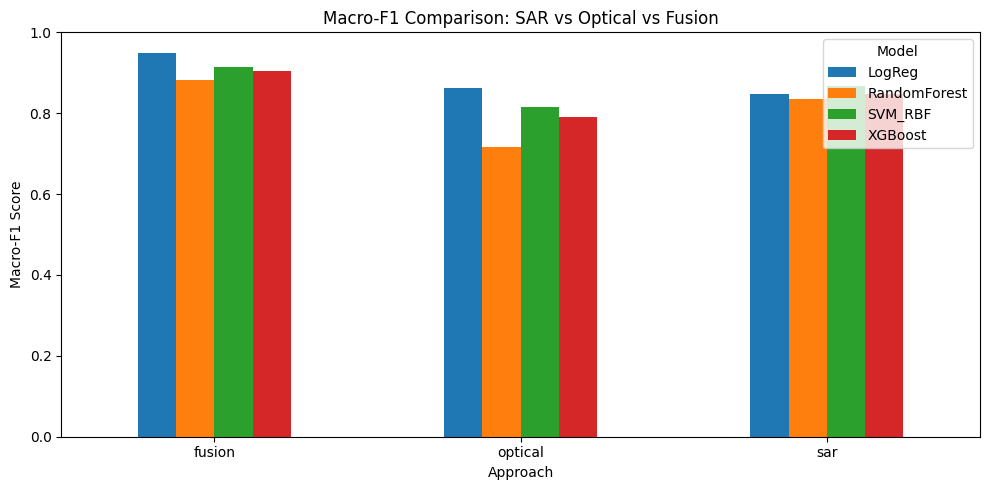

In [34]:
#Final Comparison Graph
import matplotlib.pyplot as plt

metrics = all_results.pivot(
    index="Approach",
    columns="Model",
    values="Macro_F1"
)

metrics.plot(kind="bar", figsize=(10, 5))

plt.title("Macro-F1 Comparison: SAR vs Optical vs Fusion")
plt.ylabel("Macro-F1 Score")
plt.xlabel("Approach")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig("macro_f1_comparison.png", dpi=300)
plt.show()

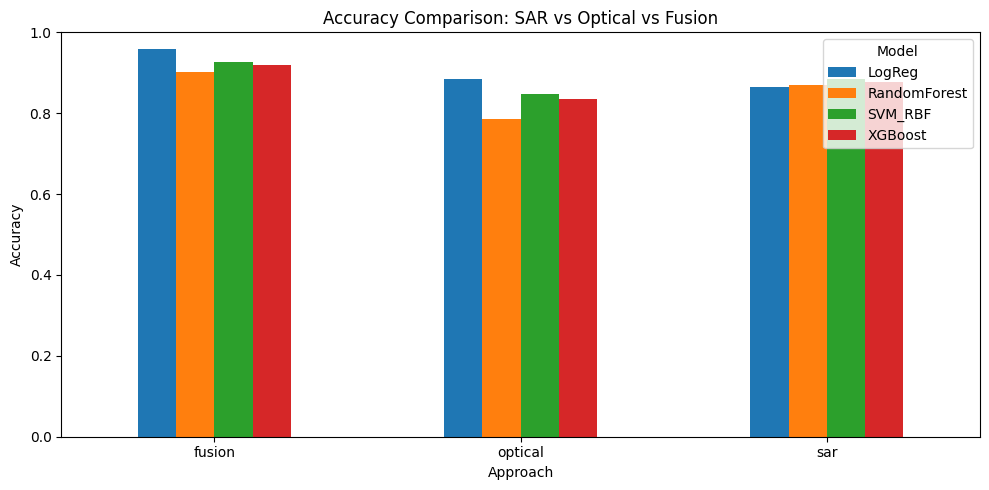

In [35]:
accuracy_metrics = all_results.pivot(
    index="Approach",
    columns="Model",
    values="Accuracy"
)

accuracy_metrics.plot(kind="bar", figsize=(10, 5))

plt.title("Accuracy Comparison: SAR vs Optical vs Fusion")
plt.ylabel("Accuracy")
plt.xlabel("Approach")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig("accuracy_comparison.png", dpi=300)
plt.show()

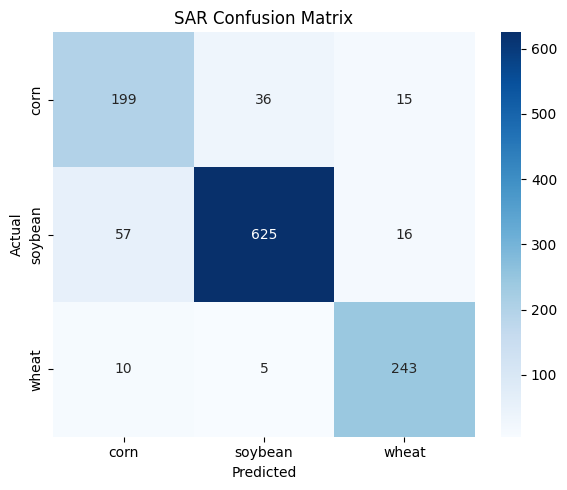

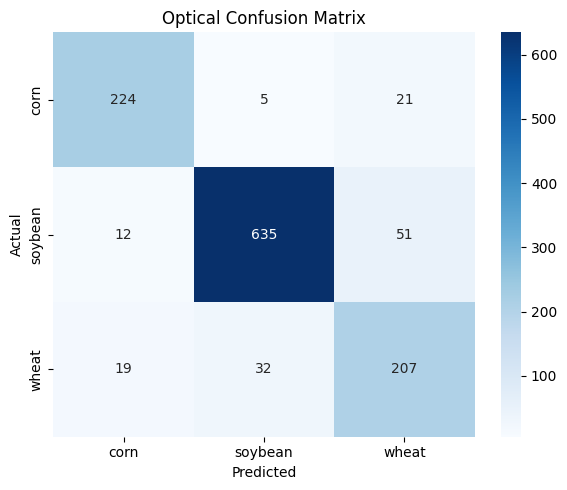

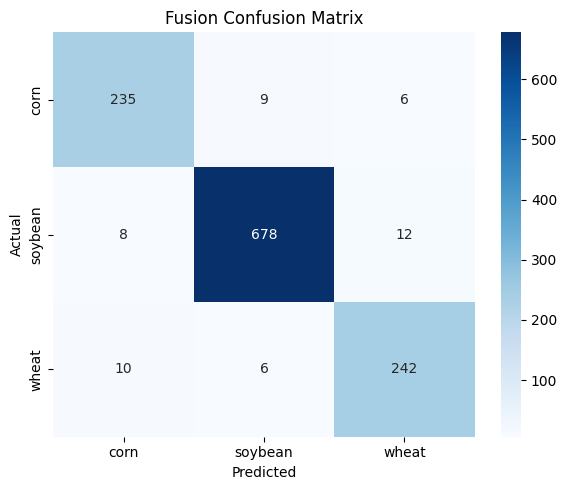

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

matrices = {
    "SAR": "results/confusion_sar_SVM_RBF.csv",
    "Optical": "results/confusion_optical_LogReg.csv",
    "Fusion": "results/confusion_fusion_LogReg.csv"
}

for name, file in matrices.items():
    cm = pd.read_csv(file, index_col=0)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()

    plt.savefig(f"{name.lower()}_confusion_matrix.png", dpi=300)
    plt.show()

In [37]:
for name, model in [
    ("sar", "SVM_RBF"),
    ("optical", "LogReg"),
    ("fusion", "LogReg")
]:
    report = pd.read_csv(
        f"results/classification_{name}_{model}.csv",
        index_col=0
    )

    print(f"\n{name.upper()} – Per-class metrics")
    display(report.loc[["corn", "soybean", "wheat"],
                       ["precision", "recall", "f1-score", "support"]])


SAR – Per-class metrics


,precision,recall,f1-score,support
corn,0.748120,0.796000,0.771318,250.0
soybean,0.938438,0.895415,0.916422,698.0
wheat,0.886861,0.941860,0.913534,258.0



OPTICAL – Per-class metrics


,precision,recall,f1-score,support
corn,0.878431,0.896000,0.887129,250.0
soybean,0.944940,0.909742,0.927007,698.0
wheat,0.741935,0.802326,0.770950,258.0



FUSION – Per-class metrics


,precision,recall,f1-score,support
corn,0.928854,0.940000,0.934394,250.0
soybean,0.978355,0.971347,0.974838,698.0
wheat,0.930769,0.937984,0.934363,258.0


In [38]:
crop_comparison = []

for name, model in [
    ("SAR", "SVM_RBF"),
    ("Optical", "LogReg"),
    ("Fusion", "LogReg")
]:
    report = pd.read_csv(
        f"results/classification_{name.lower()}_{model}.csv",
        index_col=0
    )

    for crop in ["corn", "soybean", "wheat"]:
        crop_comparison.append({
            "Approach": name,
            "Crop": crop,
            "Precision": report.loc[crop, "precision"],
            "Recall": report.loc[crop, "recall"],
            "F1": report.loc[crop, "f1-score"]
        })

crop_comparison = pd.DataFrame(crop_comparison)

crop_comparison.to_csv(
    "crop_wise_comparison.csv", index=False
)

display(crop_comparison)

,Approach,Crop,Precision,Recall,F1
0,SAR,corn,0.748120,0.796000,0.771318
1,SAR,soybean,0.938438,0.895415,0.916422
2,SAR,wheat,0.886861,0.941860,0.913534
3,Optical,corn,0.878431,0.896000,0.887129
4,Optical,soybean,0.944940,0.909742,0.927007
5,Optical,wheat,0.741935,0.802326,0.770950
6,Fusion,corn,0.928854,0.940000,0.934394
7,Fusion,soybean,0.978355,0.971347,0.974838
8,Fusion,wheat,0.930769,0.937984,0.934363
